# U.S. Inflation State-Space Modeling

**Author: QIDIAN XING**

## Economic Simulation and Model Diagnostics

**Research objective:** independently obtain both historical fits, simulate four 936-month samples from the annual fit using original seeds, and diagnose nonoverlapping annual persistence and economic adequacy.

This notebook is independent: start its kernel in notebooks/ and use Restart Kernel / Run All. No other notebook or project module is required. AI assistance is summarized in [AI Assistance and Validation](../docs/AI_Assistance_and_Validation.md).


## Parameters and fixed seeds

Monthly rates are in percentage points. Q and H are variances. Experimental settings are unchanged from the verified project.

In [1]:
from dataclasses import dataclass
from pathlib import Path
import hashlib
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from numba import njit
from scipy.optimize import minimize
from IPython.display import display, HTML

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10.5,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.2, 'figure.dpi': 120,
})
COLORS = {'monthly': '#1e4e79', 'annual': '#9b4b2b',
          'benchmark': '#52665f', 'data': '#454545'}

In [2]:
CONFIG = {'true_parameters': {'mu': 0.2, 'phi': 0.9, 'Q': 0.04, 'H': 0.01},
 'sample_lengths': [300, 3000, 300000],
 'simulation_seeds': [431300, 4313000, 431300000],
 'economic_simulation_seeds': [43101, 43102, 43103, 43104],
 'economic_sample_length': 936,
 'optimizer': {'initial_phi': [-0.5, 0.3, 0.8, 0.95],
               'maxiter': 1200,
               'gtol': 1e-08,
               'gradient_step': 1e-05},
 'hessian_steps': [0.002, 0.001, 0.0005],
 'input_csv': '../data/US_inflation47_25.csv',
 'monte_carlo': {'sample_length': 936,
                 'replications': 200,
                 'master_seed': 20261003,
                 'gradient_tolerance': 1e-06,
                 'parameter_valid_definition': 'Finite interior estimate, finite full '
                                               'likelihood, selected actual average '
                                               'gradient infinity norm < 1e-6. Optimizer '
                                               'flag is counted separately.',
                 'se_valid_definition': 'Parameter-valid plus returned fit; positive '
                                        'full-likelihood Hessian; finite positive SEs; '
                                        'original gradient and <2% step-stability criteria '
                                        'pass for all four parameters.',
                 'denominator_rule': 'All primary calibration columns use the same '
                                     'all-parameter SE-valid complete-case set; companion '
                                     'columns describe all parameter-valid estimates.',
                 'provenance': 'Predeclared supplementary uncertainty-calibration study; '
                               'independent streams and all attempts are retained.'}}

## Independent empirical fits

No estimated parameter is hardcoded and no previous notebook is required. The scalar and augmented likelihood functions below repeat the same verified implementation.

In [3]:
@dataclass(frozen=True)
class Parameters:
    mu: float
    phi: float
    Q: float
    H: float

    def __post_init__(self):
        if not (abs(self.phi) < 1 and self.Q > 0 and self.H > 0):
            raise ValueError("Require |phi|<1, Q>0 and H>0")

    def vector(self):
        return np.array([self.mu, self.phi, self.Q, self.H])

    def reported(self):
        return np.array([self.mu, self.phi, np.sqrt(self.Q), np.sqrt(self.H)])

In [4]:
def simulate(T_sample, p, seed):
    """Use a stationary initial draw and independent state/observation shocks."""
    rng = np.random.default_rng(seed)
    alpha = np.empty(T_sample)
    alpha[0] = rng.normal(0, np.sqrt(p.Q / (1 - p.phi**2)))
    epsilon = rng.normal(0, np.sqrt(p.Q), T_sample - 1)
    eta = rng.normal(0, np.sqrt(p.H), T_sample)
    for t in range(1, T_sample):
        alpha[t] = p.phi * alpha[t-1] + epsilon[t-1]
    return p.mu + alpha + eta, alpha, eta

In [5]:
def rolling_sum(y, window=12):
    """Complete windows only; keep every monthly observation date."""
    return np.convolve(np.asarray(y), np.ones(window), mode="valid")

In [6]:
def gamma_y(k, p):
    k = np.asarray(k)
    return p.Q/(1-p.phi**2)*p.phi**np.abs(k) + p.H*(k == 0)

In [7]:
def gamma_z(k, p):
    lag = k + np.arange(12)[None, :] - np.arange(12)[:, None]
    return float(gamma_y(lag, p).sum())

In [8]:
def implied_correlation(p):
    return gamma_z(12, p)/gamma_z(0, p)

In [9]:
def from_u(u):
    return Parameters(float(u[0]), float(np.tanh(u[1])),
                      float(np.exp(u[2])), float(np.exp(u[3])))

In [10]:
def to_u(p):
    return np.array([p.mu, np.arctanh(p.phi), np.log(p.Q), np.log(p.H)])

In [11]:
@njit(cache=False)
def monthly_nll_fast(y, mu, phi, Q, H):
    a = 0.0
    P = Q / (1 - phi*phi)
    nll = 0.0
    for yt in y:
        v = yt - mu - a
        F = P + H
        if F <= 0 or not np.isfinite(F):
            return np.inf
        nll += 0.5 * (np.log(2*np.pi) + np.log(F) + v*v/F)
        K = P / F
        a = phi * (a + K*v)
        P = phi*phi * (P*H/F) + Q
    return nll

In [12]:
@njit(cache=False)
def annual_nll_fast(z, mu, phi, Q, H):
    """Sparse shift recursion, O(T*24^2), equivalent to the matrix reference."""
    P = np.zeros((24, 24))
    a = np.zeros(24)
    V = Q/(1-phi*phi)
    for i in range(12):
        for j in range(12):
            P[i, j] = V*phi**abs(i-j)
        P[12+i, 12+i] = H
    previous = np.empty(24, np.int64)
    coefficient = np.ones(24)
    for i in range(24):
        previous[i] = i-1
    previous[0], coefficient[0] = 0, phi
    previous[12], coefficient[12] = 12, 0.0
    nll = 0.0
    for zt in z:
        pz = np.zeros(24)
        for i in range(24):
            for j in range(24):
                pz[i] += P[i, j]
        F = pz.sum()
        if F <= 0 or not np.isfinite(F):
            return np.inf
        v = zt - 12*mu - a.sum()
        nll += 0.5*(np.log(2*np.pi)+np.log(F)+v*v/F)
        af = a + pz*v/F
        Pf = P - np.outer(pz, pz)/F
        for i in range(24):
            a[i] = coefficient[i]*af[previous[i]]
            for j in range(24):
                P[i, j] = coefficient[i]*coefficient[j]*Pf[previous[i], previous[j]]
        P[0, 0] += Q
        P[12, 12] += H
    return nll

In [13]:
def gradient(f, x, step=1e-5):
    h = step*np.maximum(1, np.abs(x))
    g = np.empty(len(x))
    for i in range(len(x)):
        e = np.zeros(len(x)); e[i] = h[i]
        g[i] = (f(x+e)-f(x-e))/(2*h[i])
    return g

In [14]:
def hessian(f, x, step):
    h = step*np.maximum(1, np.abs(x))
    M = np.empty((len(x),len(x)))
    f0 = f(x)
    for i in range(len(x)):
        ei = np.zeros(len(x)); ei[i] = h[i]
        M[i,i] = (f(x+ei)-2*f0+f(x-ei))/h[i]**2
        for j in range(i):
            ej = np.zeros(len(x)); ej[j] = h[j]
            M[i,j] = M[j,i] = (f(x+ei+ej)-f(x+ei-ej)-f(x-ei+ej)+f(x-ei-ej))/(4*h[i]*h[j])
    return M

In [15]:
def fit(observations, kind, config, diagnostics=None):
    """Fit the unchanged MLE; optional observer retains diagnostics on failure."""
    data = np.ascontiguousarray(observations, dtype=float)
    core = monthly_nll_fast if kind == 'monthly' else annual_nll_fast
    def full_nll(u):
        # Numerical overflow guards leave the economically relevant region broad.
        if not np.isfinite(u).all() or abs(np.tanh(u[1])) >= 1 or np.any(np.abs(u[2:])>40):
            return 1e100
        p = from_u(u)
        return float(core(data, *p.vector()))
    objective = lambda u: full_nll(u)/len(data)
    cfg = config['optimizer']
    jac = lambda u: gradient(objective, u, cfg['gradient_step'])
    sample_mean = float(data.mean()/(12 if kind == 'annual' else 1))
    # Start variances are data-derived, never copied from the simulation truth.
    variance = float(np.var(data)/(80 if kind == 'annual' else 1))
    starts = []
    records = []
    for phi in cfg['initial_phi']:
        p0 = Parameters(sample_mean, phi, max(variance*0.6*(1-phi**2),1e-4),max(variance*0.4,1e-4))
        u0 = to_u(p0)
        start = time.perf_counter()
        result = minimize(objective,u0,jac=jac,method='BFGS',
                          options={'gtol':cfg['gtol'],'maxiter':cfg['maxiter']})
        records.append(dict(method='BFGS',initial_phi=phi,initial_u=u0.tolist(),
                            success=bool(result.success),message=str(result.message),
                            iterations=int(result.nit),nfev=int(result.nfev),
                            nll=full_nll(result.x),u=result.x.tolist(),
                            gradient_inf=float(np.max(np.abs(jac(result.x)))),
                            seconds=time.perf_counter()-start))
        starts.append(result)
    result = min(starts,key=lambda r:r.fun)
    u = result.x
    p = from_u(u)
    nll = full_nll(u)
    if diagnostics is not None:
        diagnostics(dict(stage='optimization', parameters=dict(mu=p.mu,phi=p.phi,Q=p.Q,H=p.H),
                         reported=p.reported().tolist(), loglik=-nll,
                         optimizer_success=bool(result.success), optimizer_message=str(result.message),
                         gradient_average_inf=float(np.max(np.abs(jac(u)))),
                         optimization_runs=records))
    hs = [hessian(full_nll,u,s) for s in config['hessian_steps']]
    I = hs[1]
    eigenvalues = np.linalg.eigvalsh(I)
    if diagnostics is not None:
        diagnostics(dict(stage='curvature',hessian=I.tolist(),eigenvalues=eigenvalues.tolist(),
                         condition_number=float(np.linalg.cond(I))))
    if eigenvalues.min() <= 0:
        raise RuntimeError(f'{kind}: actual likelihood Hessian is not positive definite: {eigenvalues}')
    covariance_u = np.linalg.solve(I,np.eye(4))
    J = np.diag([1,1-p.phi**2,np.sqrt(p.Q)/2,np.sqrt(p.H)/2])
    covariance_g = J@covariance_u@J.T
    se = np.sqrt(np.diag(covariance_g))
    Jv = np.diag([1,1-p.phi**2,p.Q,p.H])
    se_variance = np.sqrt(np.diag(Jv@covariance_u@Jv.T))
    variants = [np.sqrt(np.diag(J@np.linalg.solve(h,np.eye(4))@J.T)) for h in hs]
    se_relative_change = float(max(np.max(np.abs(v/se-1)) for v in variants))
    grad = gradient(full_nll,u,config['optimizer']['gradient_step'])
    diag = dict(hessian_steps=config['hessian_steps'],hessian=I.tolist(),
                eigenvalues=eigenvalues.tolist(),condition_number=float(np.linalg.cond(I)),
                symmetry_error=float(np.max(np.abs(I-I.T))),
                hessian_relative_changes=[float(np.linalg.norm(h-I)/np.linalg.norm(I)) for h in hs],
                se_relative_change=se_relative_change,gradient_full=grad.tolist(),
                gradient_average_inf=float(np.max(np.abs(grad))/len(data)),
                covariance_u=covariance_u.tolist(),covariance_reported=covariance_g.tolist(),
                reliable=bool(se_relative_change<0.02 and np.max(np.abs(grad))/len(data)<1e-6))
    if diagnostics is not None:
        diagnostics(dict(stage='inference',se=se.tolist(),inference=diag))
    if not diag['reliable']:
        raise RuntimeError(f'{kind}: unreliable inference diagnostics: {diag}')
    return dict(kind=kind,n=len(data),parameters=dict(mu=p.mu,phi=p.phi,Q=p.Q,H=p.H),
                sqrt_Q=np.sqrt(p.Q),sqrt_H=np.sqrt(p.H),se=se.tolist(),
                se_variances=se_variance.tolist(),u=u.tolist(),loglik=-nll,
                phi12=p.phi**12,optimizer_success=bool(result.success),
                optimizer_message=str(result.message),optimization_runs=records,
                inference=diag)

In [16]:
def parameter_table(result, truth=None):
    p = Parameters(**result['parameters'])
    table = pd.DataFrame({'Parameter': ['mu', 'phi', 'sqrt_Q', 'sqrt_H'],
                          'Estimate': p.reported(), 'SE': result['se']})
    if truth is not None:
        table.insert(1, 'True', truth.reported())
    return table


def convergence_table(results):
    return pd.DataFrame([
        {'Fit': name, 'Observations': r['n'], 'Log likelihood': r['loglik'],
         'Optimizer success': r['optimizer_success'],
         'Message': r['optimizer_message'],
         'Average gradient': r['inference']['gradient_average_inf'],
         'Minimum Hessian eigenvalue': min(r['inference']['eigenvalues']),
         'Relative SE step variation': r['inference']['se_relative_change']}
        for name, r in results.items()
    ])


def show_table(frame, digits=6):
    display(HTML(frame.to_html(index=False, float_format=lambda value: f'{value:.{digits}f}')))


def calendar_axis(axis):
    axis.xaxis.set_major_locator(mdates.YearLocator(20))
    axis.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

In [17]:
def read_and_audit_csv():
    path = Path('../data/US_inflation47_25.csv')
    if not path.is_file():
        raise FileNotFoundError('Start the kernel in the notebooks directory; the CSV is in ../data/.')
    raw = pd.read_csv(path, usecols=['Date', 'Inflation'])
    dates = pd.to_datetime(raw.Date.astype(str), format='%Y%m')
    expected = pd.date_range('1947-01-01', '2024-12-01', freq='MS')
    assert len(raw) == 936 and dates.tolist() == expected.tolist()
    assert dates.nunique() == 936 and not raw.isna().any().any()
    y = 100 * raw.Inflation.to_numpy(dtype=float)
    assert np.isfinite(y).all()
    z = rolling_sum(y)
    assert len(z) == 925
    audit_table = pd.DataFrame([
        ['Monthly observations', len(y), '1947-01', '2024-12'],
        ['Rolling annual sums', len(z), '1947-12', '2024-12'],
        ['Missing values', int(raw.isna().sum().sum()), '', ''],
        ['Zero monthly observations', int((y == 0).sum()), '', ''],
        ['Negative monthly observations', int((y < 0).sum()), '', ''],
    ], columns=['Check', 'Count', 'First date', 'Last date'])
    return dates, y, z, audit_table

In [18]:
dates, y, z, data_audit = read_and_audit_csv()
display(data_audit)
monthly_result = fit(y, 'monthly', CONFIG)
annual_result = fit(z, 'annual', CONFIG)
monthly_parameters = Parameters(**monthly_result['parameters'])
annual_parameters = Parameters(**annual_result['parameters'])
show_table(parameter_table(monthly_result))
show_table(parameter_table(annual_result))
show_table(convergence_table({'Monthly data': monthly_result,'Annual data':annual_result}))

,Check,Count,First date,Last date
0,Monthly observations,936,1947-01,2024-12
1,Rolling annual sums,925,1947-12,2024-12
2,Missing values,0,,
3,Zero monthly observations,138,,
4,Negative monthly observations,116,,


Parameter,Estimate,SE
mu,0.287164,0.027991
phi,0.752686,0.053792
sqrt_Q,0.204315,0.027249
sqrt_H,0.233854,0.019718


Parameter,Estimate,SE
mu,0.287400,0.034214
phi,0.870105,0.046242
sqrt_Q,0.132518,0.027528
sqrt_H,0.259652,0.015379


Fit,Observations,Log likelihood,Optimizer success,Message,Average gradient,Minimum Hessian eigenvalue,Relative SE step variation
Monthly data,936,-305.104716,True,Optimization terminated successfully.,0.000000,9.303286,0.000012
Annual data,925,-285.055599,True,Optimization terminated successfully.,0.000000,4.660840,0.000022


## Four paths with common axes

The annual fit estimates monthly parameters. Each original seed produces 936 monthly rates and 925 rolling annual sums; all panels use identical time and vertical scales.

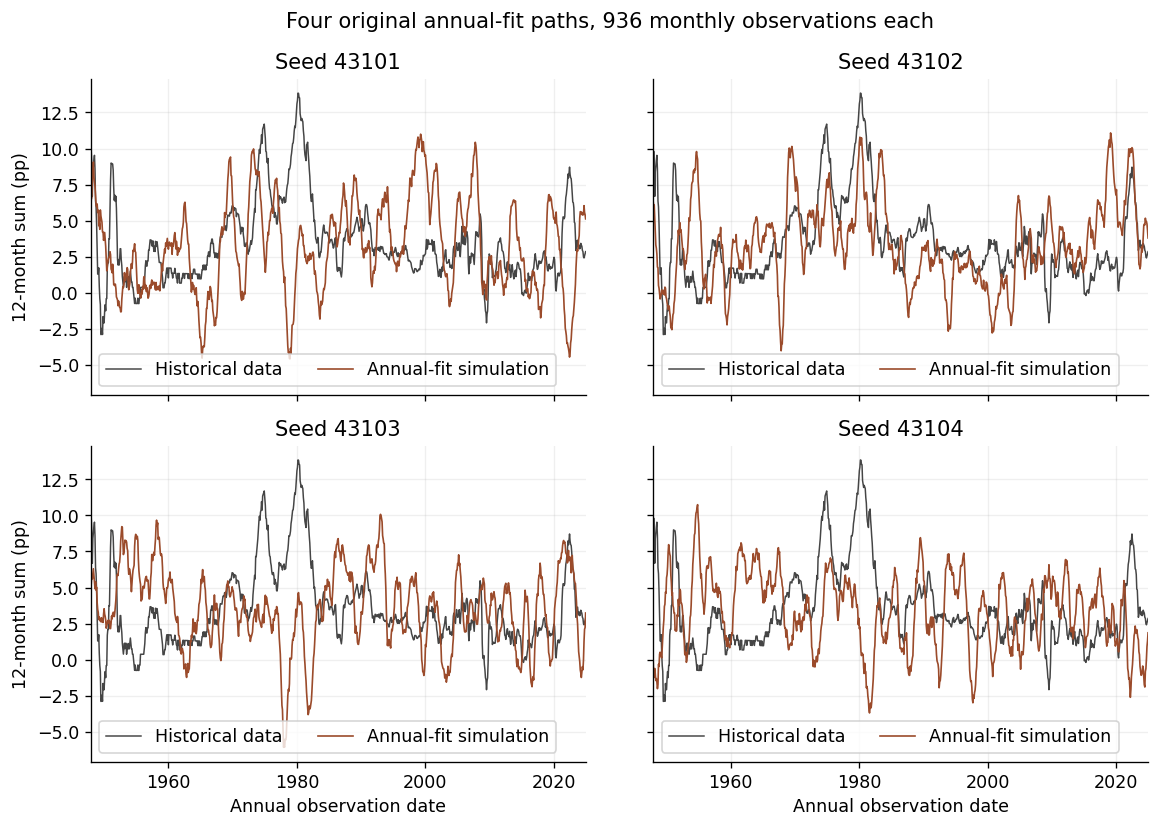

In [19]:
annual_dates = dates.iloc[11:]
economic_paths = pd.DataFrame({'date':annual_dates.dt.strftime('%Y-%m').to_numpy(),'z':z})
statistics = []
for seed in CONFIG['economic_simulation_seeds']:
    sample_y, _, _ = simulate(CONFIG['economic_sample_length'], annual_parameters, seed)
    sample_z = rolling_sum(sample_y)
    assert len(sample_y) == 936 and len(sample_z) == 925
    economic_paths[f'seed_{seed}'] = sample_z
    statistics.append({'seed':seed,'mean':float(sample_z.mean()),'sd':float(sample_z.std(ddof=1)),
                       'min':float(sample_z.min()),'max':float(sample_z.max()),
                       'rho12':float(np.corrcoef(sample_z[12:],sample_z[:-12])[0,1])})
economic_statistics = pd.DataFrame(statistics)
fig_paths, axes = plt.subplots(2,2,figsize=(10,7),sharex=True,sharey=True)
values = economic_paths.iloc[:,1:].to_numpy()
low, high = values.min(), values.max(); pad = 0.05*(high-low)
for ax, seed in zip(axes.ravel(),CONFIG['economic_simulation_seeds']):
    ax.plot(annual_dates,z,color=COLORS['data'],lw=0.9,label='Historical data')
    ax.plot(annual_dates,economic_paths[f'seed_{seed}'],color=COLORS['annual'],lw=1,label='Annual-fit simulation')
    ax.set_title(f'Seed {seed}'); ax.legend(ncol=2)
    ax.set_xlim(annual_dates.iloc[0],annual_dates.iloc[-1]); ax.set_ylim(low-pad,high+pad)
    calendar_axis(ax)
for ax in axes[:,0]:ax.set_ylabel('12-month sum (pp)')
for ax in axes[-1]:ax.set_xlabel('Annual observation date')
fig_paths.suptitle('Four original annual-fit paths, 936 monthly observations each')
fig_paths.tight_layout(); plt.show()

## Nonoverlapping annual persistence
$$\gamma_y(k)=\frac{Q}{1-\phi^2}\phi^{|k|}+H\mathbf1_{k=0},\qquad
\gamma_z(k)=\sum_{i=0}^{11}\sum_{j=0}^{11}\gamma_y(k+j-i),$$
$$\rho_z(12)=\gamma_z(12)/\gamma_z(0).$$
$z_t$ and $z_{t-12}$ share no months. Their correlation aggregates all cross-month
state covariances, while $\phi^{12}$ measures latent state decay. Observation
noise contributes to annual variance, so these measures are different.

In [20]:
persistence = pd.DataFrame([
    {'Source':'Data', 'rho_z_12':float(np.corrcoef(z[12:],z[:-12])[0,1]),
     'phi12':np.nan, 'annual_variance':float(np.var(z,ddof=1))},
    *[{'Source':name, 'rho_z_12':implied_correlation(p), 'phi12':p.phi**12,
       'annual_variance':gamma_z(0,p)} for name,p in
      [('Monthly fit implied',monthly_parameters),('Annual fit implied',annual_parameters)]]])
show_table(persistence)
show_table(economic_statistics)

Source,rho_z_12,phi12,annual_variance
Data,0.607177,NaN,7.613062
Monthly fit implied,0.169055,0.033065,6.554392
Annual fit implied,0.338949,0.188303,7.246535


seed,mean,sd,min,max,rho12
43101,3.170465,3.212685,-4.579888,10.997937,0.455419
43102,3.344830,2.900330,-4.018472,11.085501,0.378852
43103,3.564434,2.727600,-6.074326,10.073587,0.311784
43104,3.309719,2.579443,-3.693361,10.745010,0.178640


The annual fit moves implied correlation closer to historical correlation but still falls well short. Simulated paths can show substantial variation while reverting too quickly toward a fixed mean; long historical inflation episodes suggest missing persistent changes in levels or volatility. This does not establish a causal mechanism. **Implementation validation** checks likelihood recovery when the model is true; **economic diagnosis** asks whether the fitted specification describes the observed economy. Neither is the same as the latent phi^12 calculation.